In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from setuptools.command.rotate import rotate

In [3]:
df = pd.read_csv("../data/raw/cs-training.csv")
df

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
149995,149996,0,0.040674,74,0,0.225131,2100.0,4,0,1,0,0.0
149996,149997,0,0.299745,44,0,0.716562,5584.0,4,0,1,0,2.0
149997,149998,0,0.246044,58,0,3870.000000,NaN,18,0,1,0,0.0
149998,149999,0,0.000000,30,0,0.000000,5716.0,4,0,0,0,0.0


In [4]:
print(df.shape)
print(df.columns)

(150000, 12)
Index(['Unnamed: 0', 'SeriousDlqin2yrs',
       'RevolvingUtilizationOfUnsecuredLines', 'age',
       'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome',
       'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate',
       'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse',
       'NumberOfDependents'],
      dtype='object')


In [5]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 12 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   Unnamed: 0                            150000 non-null  int64  
 1   SeriousDlqin2yrs                      150000 non-null  int64  
 2   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 3   age                                   150000 non-null  int64  
 4   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 5   DebtRatio                             150000 non-null  float64
 6   MonthlyIncome                         120269 non-null  float64
 7   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 8   NumberOfTimes90DaysLate               150000 non-null  int64  
 9   NumberRealEstateLoansOrLines          150000 non-null  int64  
 10  NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 11  

In [6]:
df.describe()

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
count,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,1.202690e+05,150000.000000,150000.000000,150000.000000,150000.000000,146076.000000
mean,75000.500000,0.066840,6.048438,52.295207,0.421033,353.005076,6.670221e+03,8.452760,0.265973,1.018240,0.240387,0.757222
std,43301.414527,0.249746,249.755371,14.771866,4.192781,2037.818523,1.438467e+04,5.145951,4.169304,1.129771,4.155179,1.115086
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,37500.750000,0.000000,0.029867,41.000000,0.000000,0.175074,3.400000e+03,5.000000,0.000000,0.000000,0.000000,0.000000
50%,75000.500000,0.000000,0.154181,52.000000,0.000000,0.366508,5.400000e+03,8.000000,0.000000,1.000000,0.000000,0.000000
75%,112500.250000,0.000000,0.559046,63.000000,0.000000,0.868254,8.249000e+03,11.000000,0.000000,2.000000,0.000000,1.000000
max,150000.000000,1.000000,50708.000000,109.000000,98.000000,329664.000000,3.008750e+06,58.000000,98.000000,54.000000,98.000000,20.000000


In [7]:
print(df["Unnamed: 0"].nunique())
print(df["SeriousDlqin2yrs"].value_counts())
print(df["SeriousDlqin2yrs"].value_counts(normalize=True) * 100)


150000
SeriousDlqin2yrs
0    139974
1     10026
Name: count, dtype: int64
SeriousDlqin2yrs
0    93.316
1     6.684
Name: proportion, dtype: float64


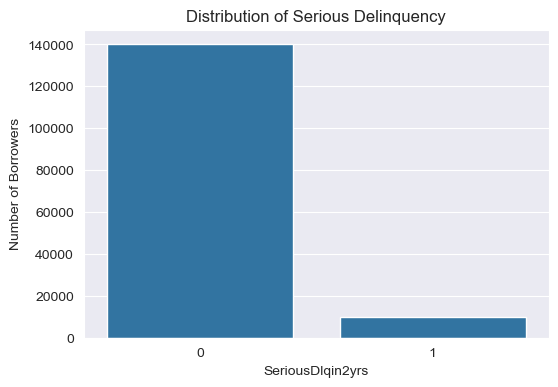

In [8]:
plt.figure(figsize=(6,4))

sns.countplot(data = df , x = "SeriousDlqin2yrs")

plt.title("Distribution of Serious Delinquency")
plt.xlabel("SeriousDlqin2yrs")
plt.ylabel("Number of Borrowers")

plt.show()

### Target Distribution

The target variable `SeriousDlqin2yrs` is highly imbalanced.
There are 139,974 negative cases (93.316%) and 10,026 positive
cases (6.684%).

Therefore, accuracy alone would be misleading for evaluating
the models. We will focus primarily on PR-AUC and ROC-AUC,
along with precision, recall, F1 score, and cost-based evaluation.

The `Unnamed: 0` column contains 150,000 unique values for
150,000 observations and appears to be a row identifier rather
than a meaningful predictive feature. It will be removed during
the feature-engineering stage.

### Missing Value

In [9]:
missing = pd.DataFrame({
    "Missing Count" : df.isnull().sum(),
    "Missing Percentage" : df.isnull().mean() * 100
})
missing.sort_values("Missing Count", ascending=False)

,Missing Count,Missing Percentage
MonthlyIncome,29731,19.820667
NumberOfDependents,3924,2.616000
Unnamed: 0,0,0.000000
SeriousDlqin2yrs,0,0.000000
age,0,0.000000
RevolvingUtilizationOfUnsecuredLines,0,0.000000
DebtRatio,0,0.000000
NumberOfTime30-59DaysPastDueNotWorse,0,0.000000
NumberOfOpenCreditLinesAndLoans,0,0.000000
NumberOfTimes90DaysLate,0,0.000000


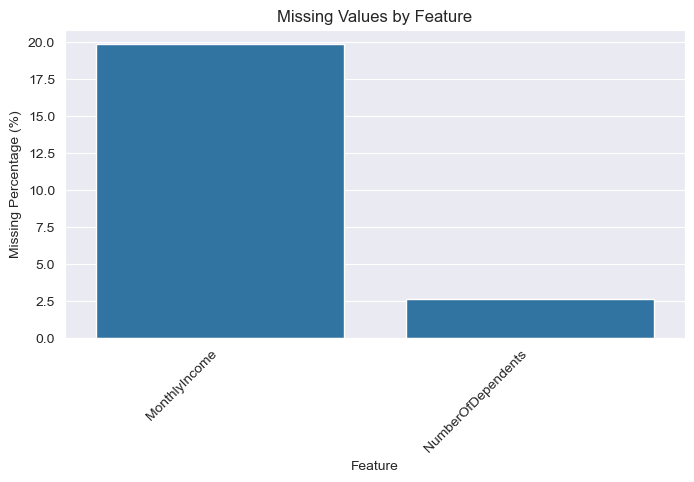

In [10]:
missing_plot = missing[missing["Missing Count"] > 0]

plt.figure(figsize=(8,4))

sns.barplot(
    x = missing_plot.index,
    y = missing_plot["Missing Percentage"]
)
plt.title("Missing Values by Feature")
plt.ylabel("Missing Percentage (%)")
plt.xlabel("Feature")

plt.xticks(rotation = 45 , ha = "right")
plt.show()


In [11]:
df.groupby(df["MonthlyIncome"].isna())["SeriousDlqin2yrs"].agg(
    ["count" , "mean"]
)

,count,mean
MonthlyIncome,,
False,120269,0.069486
True,29731,0.056137


### Missing Value Analysis

`MonthlyIncome` has 29,731 missing observations, representing
19.82% of the dataset. `NumberOfDependents` has 3,924 missing
observations, representing 2.62%. All other variables contain
no missing values.

The missingness of `MonthlyIncome` was also compared with the
target variable. Borrowers with recorded income have a serious
delinquency rate of 6.95%, while borrowers with missing income
have a rate of 5.61%.

Therefore, missing income is not simply associated with higher
default risk. However, the difference in target rates indicates
that the missingness pattern itself may contain predictive
information. The final treatment of missing values will be
determined during the cleaning and feature-engineering stage.

### Duplicate Analysis

In [12]:
df.duplicated().sum()


np.int64(0)

In [13]:
feature_cols = df.columns.drop(["Unnamed: 0", "SeriousDlqin2yrs"])

In [14]:
conflicting_groups = (
    df.groupby(list(feature_cols))["SeriousDlqin2yrs"].nunique()
)

conflicting_groups[conflicting_groups > 1].shape[0]

2

### Duplicate Analysis

There are no complete duplicate rows in the raw dataset.

After removing the `Unnamed: 0` identifier, 609 duplicate
feature-and-target combinations were found. These observations
were retained because identical recorded borrower characteristics
can legitimately occur for different observations.

A further check found 2 unique feature combinations associated
with both target classes. These conflicting labels indicate that
the available features do not completely determine the target and
that some uncertainty remains in the prediction problem.

No observations are removed at this stage. Any treatment of
duplicates will be considered during data preparation.

### Feature Distribution

In [15]:
df["age"].describe()


count    150000.000000
mean         52.295207
std          14.771866
min           0.000000
25%          41.000000
50%          52.000000
75%          63.000000
max         109.000000
Name: age, dtype: float64

In [16]:
df["age"].value_counts().sort_index().head(15)

age
0        1
21     183
22     434
23     641
24     816
25     953
26    1193
27    1338
28    1560
29    1702
30    1937
31    2038
32    2050
33    2239
34    2155
Name: count, dtype: int64

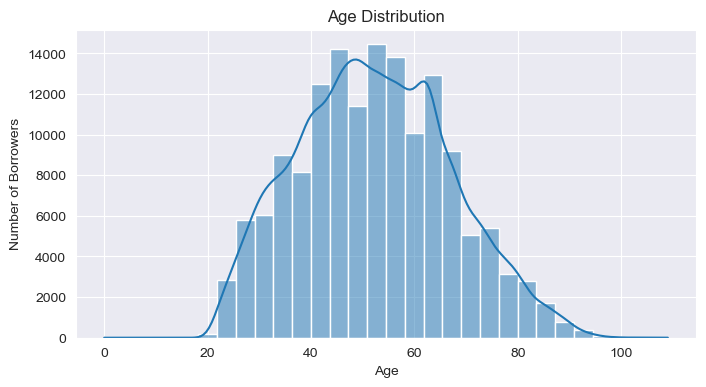

In [17]:
plt.figure(figsize=(8,4))

sns.histplot(data = df , x='age' , bins = 30 , kde=True)

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Borrowers")

plt.show()

In [18]:
df[df["age"] >= 90]["age"].value_counts().sort_index()


age
90     198
91     154
92      93
93      87
94      47
95      45
96      18
97      17
98       6
99       9
101      3
102      3
103      3
105      1
107      1
109      2
Name: count, dtype: int64

### Age Upper Tail

The upper tail contains relatively few observations. There are
198 borrowers aged 90, with the frequency decreasing substantially
at higher ages. Ages above 100 are extremely rare, with only a few
observations between 101 and 109.

These extreme ages are not automatically treated as invalid because
their values do not exhibit an obvious placeholder-code pattern.
The age value of 0 remains the clearest suspicious observation and
will be investigated during cleaning.

### Age Distribution

The age variable has a median of 52 years and ranges from 0 to
109 years. The distribution is concentrated mainly between
approximately 20 and 80 years, with most observations occurring
around the 40–65 year range.

One observation has an age of 0, which is clearly suspicious
because the main distribution begins around adulthood. The
maximum age of 109 is extreme but is not automatically treated
as invalid at this stage.

The suspicious age value will be investigated and handled during
the cleaning and feature-engineering stage rather than being
modified during EDA.

In [19]:
df["RevolvingUtilizationOfUnsecuredLines"].describe()


count    150000.000000
mean          6.048438
std         249.755371
min           0.000000
25%           0.029867
50%           0.154181
75%           0.559046
max       50708.000000
Name: RevolvingUtilizationOfUnsecuredLines, dtype: float64

In [20]:
df["RevolvingUtilizationOfUnsecuredLines"].value_counts().head(15)


RevolvingUtilizationOfUnsecuredLines
0.000000    10878
1.000000    10256
1.000000       17
0.950100        8
0.007984        6
0.713147        6
0.954092        6
0.796407        5
0.046048        5
0.538922        5
0.988024        5
0.004999        5
0.582834        5
0.850299        5
0.717131        5
Name: count, dtype: int64

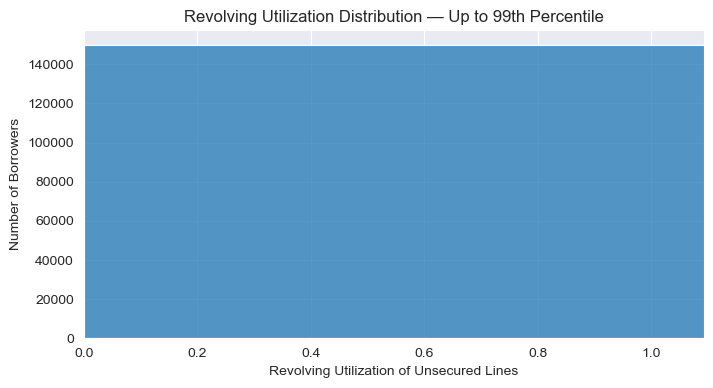

In [21]:
upper_99 = df["RevolvingUtilizationOfUnsecuredLines"].quantile(0.99)

plt.figure(figsize=(8, 4))

sns.histplot(
    data=df,
    x="RevolvingUtilizationOfUnsecuredLines",
    bins=50
)

plt.xlim(0, upper_99)

plt.title("Revolving Utilization Distribution — Up to 99th Percentile")
plt.xlabel("Revolving Utilization of Unsecured Lines")
plt.ylabel("Number of Borrowers")

plt.show()

In [22]:
df["RevolvingUtilizationOfUnsecuredLines"].quantile(
    [0.90, 0.95, 0.99, 0.995, 0.999]
)

0.900       0.981278
0.950       1.000000
0.990       1.092956
0.995       1.366269
0.999    1571.006000
Name: RevolvingUtilizationOfUnsecuredLines, dtype: float64

In [23]:
df.nlargest(
    15,
    "RevolvingUtilizationOfUnsecuredLines"
)[
    [
        "RevolvingUtilizationOfUnsecuredLines",
        "age",
        "DebtRatio",
        "MonthlyIncome",
        "SeriousDlqin2yrs"
    ]
]

,RevolvingUtilizationOfUnsecuredLines,age,DebtRatio,MonthlyIncome,SeriousDlqin2yrs
85489,50708.0,55,0.221757,38000.0,0
31414,29110.0,58,0.402560,10000.0,0
16956,22198.0,38,2312.000000,NaN,0
149160,22000.0,38,1.080020,3973.0,0
149279,20514.0,42,0.062102,9902.0,0
117315,18300.0,45,0.221582,12500.0,0
21978,17441.0,51,0.354072,14770.0,0
124533,13930.0,45,4902.000000,NaN,0
72592,13498.0,38,0.347428,4800.0,0
71705,13400.0,43,0.995801,5000.0,0


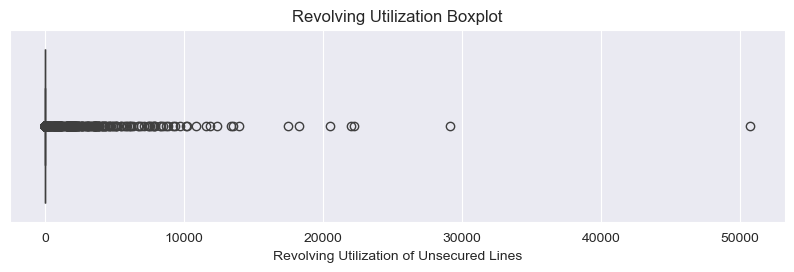

In [24]:
plt.figure(figsize=(10, 2.5))

sns.boxplot(
    x=df["RevolvingUtilizationOfUnsecuredLines"]
)

plt.title("Revolving Utilization Boxplot")
plt.xlabel("Revolving Utilization of Unsecured Lines")

plt.show()

### Revolving Utilization Analysis

`RevolvingUtilizationOfUnsecuredLines` is highly right-skewed.
The 90th percentile is 0.981, the 95th percentile is 1.0, and
the 99th percentile is 1.093. However, the 99.9th percentile
increases sharply to 1571.006, with a maximum value of 50708.

This indicates a very long extreme right tail. The 15 largest
observations all have a target value of 0, although this small
number of observations is insufficient to infer a relationship
between extreme utilization and default risk.

Several extreme observations also have missing `MonthlyIncome`.
The extreme utilization values are retained during EDA and will
be investigated further before any preprocessing decision is made.

In [25]:
df["DebtRatio"].describe()


count    150000.000000
mean        353.005076
std        2037.818523
min           0.000000
25%           0.175074
50%           0.366508
75%           0.868254
max      329664.000000
Name: DebtRatio, dtype: float64

In [26]:
df["DebtRatio"].quantile(
    [0.90, 0.95, 0.99, 0.995, 0.999]
)

0.900     1267.000
0.950     2449.000
0.990     4979.040
0.995     6186.010
0.999    10613.074
Name: DebtRatio, dtype: float64

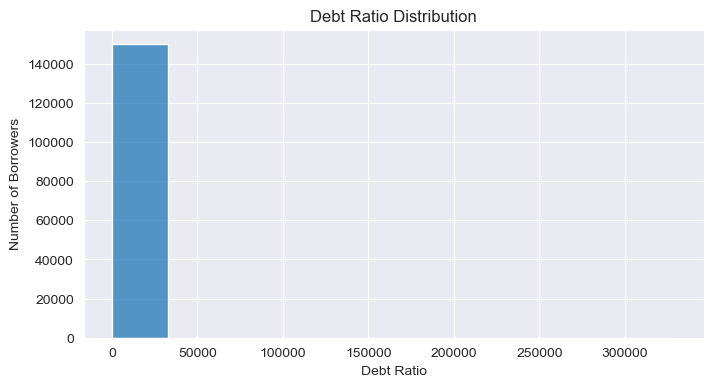

In [27]:
plt.figure(figsize=(8, 4))

sns.histplot(
    data=df,
    x="DebtRatio",
    bins=10
)

plt.title("Debt Ratio Distribution")
plt.xlabel("Debt Ratio")
plt.ylabel("Number of Borrowers")

plt.show()

In [28]:
df.nlargest(
    15,
    "DebtRatio"
)[
    [
        "DebtRatio",
        "age",
        "RevolvingUtilizationOfUnsecuredLines",
        "MonthlyIncome",
        "SeriousDlqin2yrs"
    ]
]

,DebtRatio,age,RevolvingUtilizationOfUnsecuredLines,MonthlyIncome,SeriousDlqin2yrs
60152,329664.0,65,0.000000,NaN,0
36600,326442.0,65,0.001782,NaN,0
127047,307001.0,58,0.034290,NaN,0
58900,220516.0,37,0.182640,NaN,0
4854,168835.0,56,0.000000,NaN,0
7513,110952.0,71,0.152293,NaN,0
103041,106885.0,65,0.364845,NaN,0
69845,101320.0,66,0.386451,NaN,0
66785,61907.0,63,1.000000,NaN,0
53682,61106.5,89,1.000000,1.0,0


### Debt Ratio Analysis

`DebtRatio` is extremely right-skewed. Its median is 0.367 and
its 75th percentile is 0.868, while the 90th percentile is already
1267 and the maximum reaches 329664.

Inspection of the largest observations reveals a strong association
between extremely large DebtRatio values and missing `MonthlyIncome`.
Several of the largest DebtRatio observations have no recorded
monthly income, while a small number have MonthlyIncome equal to 0.

The largest DebtRatio observations also have relatively ordinary
values of `RevolvingUtilizationOfUnsecuredLines`, suggesting that
the extreme behavior of these two features is not necessarily
driven by the same observations.

All 15 of the largest DebtRatio observations have a target value of
0. This observation is descriptive only and is not interpreted as
evidence that extreme DebtRatio reduces default risk.

The extreme DebtRatio values are therefore retained during EDA.
Their treatment will be determined during the cleaning and feature
engineering stage after further investigation.

In [29]:
df["NumberOfTime30-59DaysPastDueNotWorse"].describe()


count    150000.000000
mean          0.421033
std           4.192781
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max          98.000000
Name: NumberOfTime30-59DaysPastDueNotWorse, dtype: float64

In [30]:
df["NumberOfTime30-59DaysPastDueNotWorse"].value_counts().sort_index()


NumberOfTime30-59DaysPastDueNotWorse
0     126018
1      16033
2       4598
3       1754
4        747
5        342
6        140
7         54
8         25
9         12
10         4
11         1
12         2
13         1
96         5
98       264
Name: count, dtype: int64

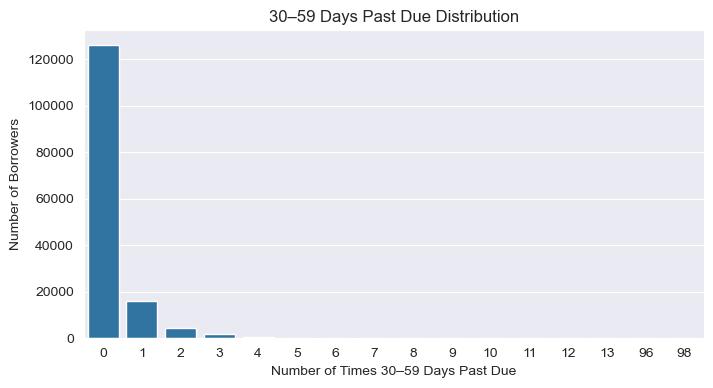

In [31]:
plt.figure(figsize=(8, 4))

sns.countplot(
    data=df,
    x="NumberOfTime30-59DaysPastDueNotWorse"
)

plt.title("30–59 Days Past Due Distribution")
plt.xlabel("Number of Times 30–59 Days Past Due")
plt.ylabel("Number of Borrowers")

plt.show()

In [32]:
df[df["NumberOfTime30-59DaysPastDueNotWorse"].isin([96, 98])][
    [
        "NumberOfTime30-59DaysPastDueNotWorse",
        "NumberOfTime60-89DaysPastDueNotWorse",
        "NumberOfTimes90DaysLate",
        "SeriousDlqin2yrs"
    ]
].value_counts()

NumberOfTime30-59DaysPastDueNotWorse  NumberOfTime60-89DaysPastDueNotWorse  NumberOfTimes90DaysLate  SeriousDlqin2yrs
98                                    98                                    98                       1                   143
                                                                                                     0                   121
96                                    96                                    96                       1                     4
                                                                                                     0                     1
Name: count, dtype: int64

In [33]:
df[df["NumberOfTime30-59DaysPastDueNotWorse"].isin([96, 98])][
    [
        "NumberOfTime30-59DaysPastDueNotWorse",
        "NumberOfTime60-89DaysPastDueNotWorse",
        "NumberOfTimes90DaysLate"
    ]
].drop_duplicates()

,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTime60-89DaysPastDueNotWorse,NumberOfTimes90DaysLate
1733,98,98,98
41944,96,96,96


### Suspicious Delinquency Values

The 30–59 days past-due variable contains unusual values of 96
and 98. Normal observations range from 0 to 13, followed by a
large gap before 96 and 98.

Further investigation shows that these values occur
simultaneously across all three delinquency variables. The
distinct suspicious combinations are (96, 96, 96) and
(98, 98, 98).

This repeated pattern strongly suggests that 96 and 98 are
special encoded values rather than ordinary delinquency counts.
Their exact meaning is not assumed during EDA and their treatment
will be determined during the cleaning and feature-engineering
stage.

In [34]:
df["NumberOfTime60-89DaysPastDueNotWorse"].describe()


count    150000.000000
mean          0.240387
std           4.155179
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max          98.000000
Name: NumberOfTime60-89DaysPastDueNotWorse, dtype: float64

In [35]:
df["NumberOfTime60-89DaysPastDueNotWorse"].value_counts().sort_index()


NumberOfTime60-89DaysPastDueNotWorse
0     142396
1       5731
2       1118
3        318
4        105
5         34
6         16
7          9
8          2
9          1
11         1
96         5
98       264
Name: count, dtype: int64

In [36]:
df["NumberOfTimes90DaysLate"].describe()


count    150000.000000
mean          0.265973
std           4.169304
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max          98.000000
Name: NumberOfTimes90DaysLate, dtype: float64

In [37]:
df["NumberOfTimes90DaysLate"].value_counts().sort_index()


NumberOfTimes90DaysLate
0     141662
1       5243
2       1555
3        667
4        291
5        131
6         80
7         38
8         21
9         19
10         8
11         5
12         2
13         4
14         2
15         2
17         1
96         5
98       264
Name: count, dtype: int64

### 90+ Days Late Analysis

The `NumberOfTimes90DaysLate` variable is strongly concentrated at
zero. 141,662 observations, approximately 94.4% of the dataset,
have no recorded 90+ day delinquency.

The normal-looking values gradually decrease in frequency from 1
through 17, with no observations between 18 and 95. Values of 96
and 98 then appear with frequencies of 5 and 264 respectively.

The same frequencies of 96 and 98 are observed in the 30–59 day,
60–89 day, and 90+ day delinquency variables. Previous investigation
also showed that these suspicious values occur simultaneously across
all three variables as (96, 96, 96) and (98, 98, 98).

This consistent pattern strongly suggests that 96 and 98 represent
special encoded values rather than ordinary delinquency counts.
Their exact meaning is not assumed during EDA; treatment will be
decided during the cleaning and feature-engineering stage.

In [38]:
df["NumberOfOpenCreditLinesAndLoans"].describe()


count    150000.000000
mean          8.452760
std           5.145951
min           0.000000
25%           5.000000
50%           8.000000
75%          11.000000
max          58.000000
Name: NumberOfOpenCreditLinesAndLoans, dtype: float64

In [39]:
df["NumberOfOpenCreditLinesAndLoans"].value_counts().sort_index()


NumberOfOpenCreditLinesAndLoans
0      1888
1      4438
2      6666
3      9058
4     11609
5     12931
6     13614
7     13245
8     12562
9     11355
10     9624
11     8321
12     7005
13     5667
14     4546
15     3645
16     3000
17     2370
18     1874
19     1433
20     1169
21      864
22      685
23      533
24      422
25      337
26      239
27      194
28      150
29      114
30       88
31       74
32       52
33       47
34       35
35       27
36       18
37        7
38       13
39        9
40       10
41        4
42        8
43        8
44        2
45        8
46        3
47        2
48        6
49        4
50        2
51        2
52        3
53        1
54        4
56        2
57        2
58        1
Name: count, dtype: int64

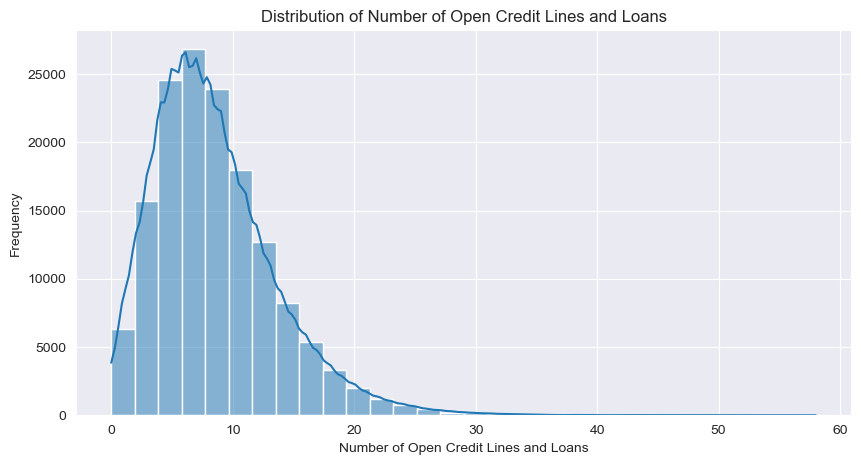

In [40]:
plt.figure(figsize=(10, 5))
sns.histplot(df["NumberOfOpenCreditLinesAndLoans"], bins=30 , kde=True)
plt.xlabel("Number of Open Credit Lines and Loans")
plt.ylabel("Frequency")
plt.title("Distribution of Number of Open Credit Lines and Loans")
plt.show()

In [41]:
df[df["NumberOfOpenCreditLinesAndLoans"] >= 40][
    [
        "NumberOfOpenCreditLinesAndLoans",
        "age",
        "DebtRatio",
        "MonthlyIncome",
        "SeriousDlqin2yrs"
    ]
].sort_values("NumberOfOpenCreditLinesAndLoans", ascending=False)

,NumberOfOpenCreditLinesAndLoans,age,DebtRatio,MonthlyIncome,SeriousDlqin2yrs
30587,58,53,5.967504,8000.0,0
22683,57,51,0.032213,3600.0,0
137095,57,42,0.100814,42156.0,1
107427,56,48,0.025088,7373.0,0
51026,56,70,0.074935,8900.0,0
...,...,...,...,...,...
77449,40,58,0.478539,3750.0,0
36405,40,49,0.577642,10000.0,0
99315,40,52,0.169603,10500.0,0
141114,40,47,0.671636,24883.0,0


In [42]:
df["NumberRealEstateLoansOrLines"].describe()

count    150000.000000
mean          1.018240
std           1.129771
min           0.000000
25%           0.000000
50%           1.000000
75%           2.000000
max          54.000000
Name: NumberRealEstateLoansOrLines, dtype: float64

In [43]:
df["NumberRealEstateLoansOrLines"].value_counts().sort_index()


NumberRealEstateLoansOrLines
0     56188
1     52338
2     31522
3      6300
4      2170
5       689
6       320
7       171
8        93
9        78
10       37
11       23
12       18
13       15
14        7
15        7
16        4
17        4
18        2
19        2
20        2
21        1
23        2
25        3
26        1
29        1
32        1
54        1
Name: count, dtype: int64

In [44]:
df[df["NumberRealEstateLoansOrLines"] >= 20][
    [
        "NumberRealEstateLoansOrLines",
        "age",
        "RevolvingUtilizationOfUnsecuredLines",
        "DebtRatio",
        "MonthlyIncome",
        "NumberOfOpenCreditLinesAndLoans",
        "SeriousDlqin2yrs"
    ]
].sort_values("NumberRealEstateLoansOrLines", ascending=False)

,NumberRealEstateLoansOrLines,age,RevolvingUtilizationOfUnsecuredLines,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,SeriousDlqin2yrs
30587,54,53,0.003032,5.967504,8000.0,58,0
104198,32,60,0.010846,1.041757,70000.0,38,0
65728,29,43,0.036942,0.719174,55966.0,41,1
18259,26,61,0.635363,0.429449,48000.0,33,0
123746,25,51,0.985390,0.515205,56000.0,42,0
68909,25,44,0.297748,1.237481,12400.0,42,0
103893,25,44,0.507886,0.467231,37000.0,33,1
46102,23,76,0.003928,52112.000000,NaN,27,0
62192,23,73,0.002280,3.593683,14500.0,26,0
31517,21,38,0.060621,0.505055,33334.0,29,0


In [45]:
df["NumberOfDependents"].describe()


count    146076.000000
mean          0.757222
std           1.115086
min           0.000000
25%           0.000000
50%           0.000000
75%           1.000000
max          20.000000
Name: NumberOfDependents, dtype: float64

In [46]:
df["NumberOfDependents"].value_counts(dropna=False).sort_index()


NumberOfDependents
0.0     86902
1.0     26316
2.0     19522
3.0      9483
4.0      2862
5.0       746
6.0       158
7.0        51
8.0        24
9.0         5
10.0        5
13.0        1
20.0        1
NaN      3924
Name: count, dtype: int64

In [47]:
df.groupby(df["NumberOfDependents"].isna())["SeriousDlqin2yrs"].agg(
    ["count", "mean"]
)

,count,mean
NumberOfDependents,,
False,146076,0.067410
True,3924,0.045617


## Target Relationship

In [48]:
age_default = df.groupby("age")["SeriousDlqin2yrs"].mean()

age_default

age
0      0.000000
21     0.071038
22     0.082949
23     0.109204
24     0.120098
         ...   
102    0.000000
103    0.000000
105    0.000000
107    0.000000
109    0.000000
Name: SeriousDlqin2yrs, Length: 86, dtype: float64

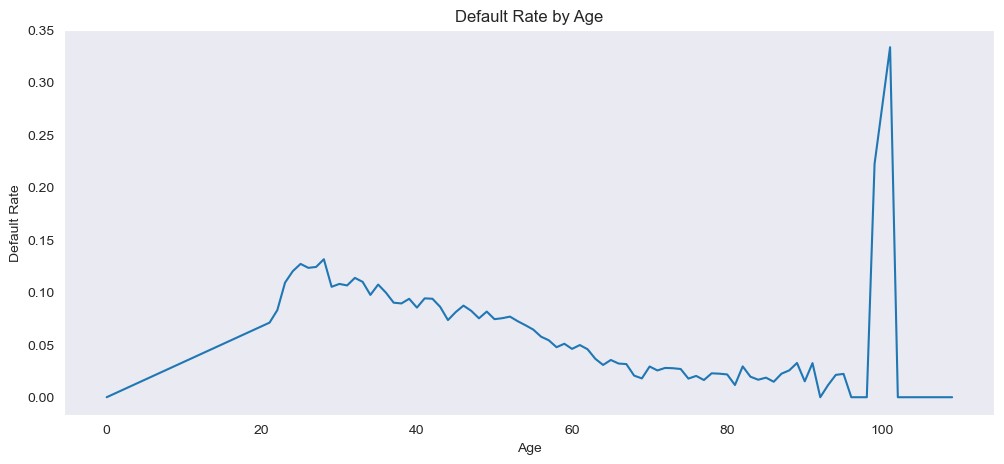

In [49]:
plt.figure(figsize=(12, 5))

plt.plot(age_default.index, age_default.values)

plt.xlabel("Age")
plt.ylabel("Default Rate")
plt.title("Default Rate by Age")
plt.grid()
plt.show()

In [50]:
df.groupby(
    "NumberOfTime30-59DaysPastDueNotWorse"
)["SeriousDlqin2yrs"].mean()

NumberOfTime30-59DaysPastDueNotWorse
0     0.040002
1     0.150253
2     0.265115
3     0.352338
4     0.425703
5     0.450292
6     0.528571
7     0.518519
8     0.320000
9     0.333333
10    0.750000
11    1.000000
12    0.500000
13    1.000000
96    0.800000
98    0.541667
Name: SeriousDlqin2yrs, dtype: float64

In [51]:
df.groupby(
    "NumberOfTimes90DaysLate"
)["SeriousDlqin2yrs"].mean()

NumberOfTimes90DaysLate
0     0.046265
1     0.336639
2     0.499035
3     0.577211
4     0.670103
5     0.633588
6     0.600000
7     0.815789
8     0.714286
9     0.736842
10    0.625000
11    0.600000
12    0.500000
13    0.500000
14    0.500000
15    0.000000
17    1.000000
96    0.800000
98    0.541667
Name: SeriousDlqin2yrs, dtype: float64

In [52]:
df.groupby(
    "NumberOfOpenCreditLinesAndLoans"
)["SeriousDlqin2yrs"].mean()

NumberOfOpenCreditLinesAndLoans
0     0.256356
1     0.131816
2     0.091359
3     0.075293
4     0.064002
5     0.063336
6     0.055384
7     0.056399
8     0.048241
9     0.058476
10    0.059643
11    0.056604
12    0.063098
13    0.054526
14    0.065992
15    0.077366
16    0.068667
17    0.066245
18    0.070971
19    0.057920
20    0.082977
21    0.069444
22    0.067153
23    0.080675
24    0.059242
25    0.050445
26    0.092050
27    0.077320
28    0.046667
29    0.070175
30    0.113636
31    0.054054
32    0.038462
33    0.085106
34    0.028571
35    0.037037
36    0.166667
37    0.142857
38    0.000000
39    0.111111
40    0.100000
41    0.250000
42    0.000000
43    0.125000
44    0.000000
45    0.125000
46    0.000000
47    0.000000
48    0.333333
49    0.250000
50    0.000000
51    0.000000
52    0.333333
53    0.000000
54    0.000000
56    0.000000
57    0.500000
58    0.000000
Name: SeriousDlqin2yrs, dtype: float64

In [53]:
pd.crosstab(
    df["NumberOfTimes90DaysLate"],
    df["SeriousDlqin2yrs"],
    normalize="index"
)

SeriousDlqin2yrs,0,1
NumberOfTimes90DaysLate,,
0,0.953735,0.046265
1,0.663361,0.336639
2,0.500965,0.499035
3,0.422789,0.577211
4,0.329897,0.670103
5,0.366412,0.633588
6,0.400000,0.600000
7,0.184211,0.815789
8,0.285714,0.714286


In [54]:
df[[
    "NumberOfTimes90DaysLate",
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "SeriousDlqin2yrs"
]].head(20)

,NumberOfTimes90DaysLate,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTime60-89DaysPastDueNotWorse,SeriousDlqin2yrs
0,0,2,0,1
1,0,0,0,0
2,1,1,0,0
3,0,0,0,0
4,0,1,0,0
5,0,0,0,0
6,0,0,0,0
7,0,0,0,0
8,0,0,0,0
9,0,0,0,0


In [55]:
df.groupby(
    "NumberOfOpenCreditLinesAndLoans"
)["SeriousDlqin2yrs"].mean()

NumberOfOpenCreditLinesAndLoans
0     0.256356
1     0.131816
2     0.091359
3     0.075293
4     0.064002
5     0.063336
6     0.055384
7     0.056399
8     0.048241
9     0.058476
10    0.059643
11    0.056604
12    0.063098
13    0.054526
14    0.065992
15    0.077366
16    0.068667
17    0.066245
18    0.070971
19    0.057920
20    0.082977
21    0.069444
22    0.067153
23    0.080675
24    0.059242
25    0.050445
26    0.092050
27    0.077320
28    0.046667
29    0.070175
30    0.113636
31    0.054054
32    0.038462
33    0.085106
34    0.028571
35    0.037037
36    0.166667
37    0.142857
38    0.000000
39    0.111111
40    0.100000
41    0.250000
42    0.000000
43    0.125000
44    0.000000
45    0.125000
46    0.000000
47    0.000000
48    0.333333
49    0.250000
50    0.000000
51    0.000000
52    0.333333
53    0.000000
54    0.000000
56    0.000000
57    0.500000
58    0.000000
Name: SeriousDlqin2yrs, dtype: float64

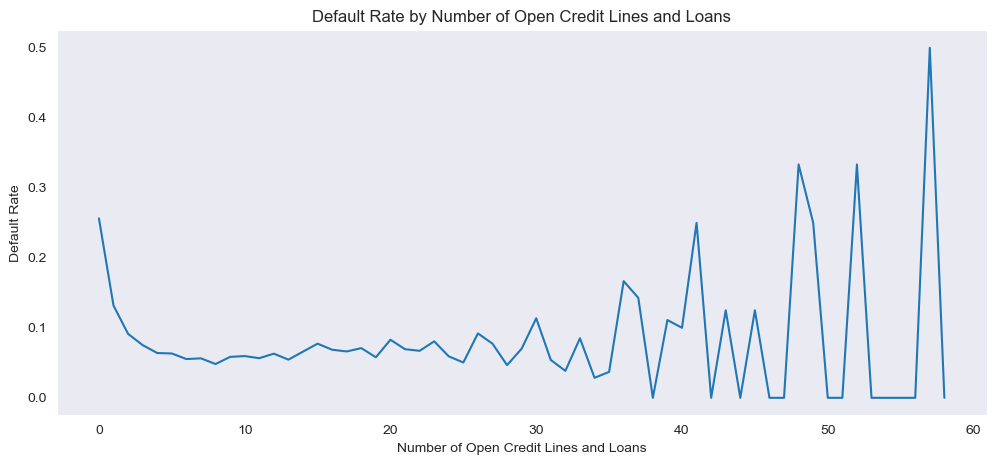

In [56]:
credit_default = df.groupby(
    "NumberOfOpenCreditLinesAndLoans"
)["SeriousDlqin2yrs"].mean()

plt.figure(figsize=(12, 5))
plt.plot(credit_default.index, credit_default.values)
plt.xlabel("Number of Open Credit Lines and Loans")
plt.ylabel("Default Rate")
plt.title("Default Rate by Number of Open Credit Lines and Loans")
plt.grid()
plt.show()

In [57]:
df.groupby("NumberRealEstateLoansOrLines")["SeriousDlqin2yrs"].mean()


NumberRealEstateLoansOrLines
0     0.083149
1     0.052505
2     0.055993
3     0.066984
4     0.089401
5     0.120464
6     0.150000
7     0.181287
8     0.247312
9     0.179487
10    0.135135
11    0.086957
12    0.333333
13    0.333333
14    0.000000
15    0.428571
16    0.250000
17    0.250000
18    0.000000
19    0.000000
20    0.500000
21    0.000000
23    0.000000
25    0.333333
26    0.000000
29    1.000000
32    0.000000
54    0.000000
Name: SeriousDlqin2yrs, dtype: float64

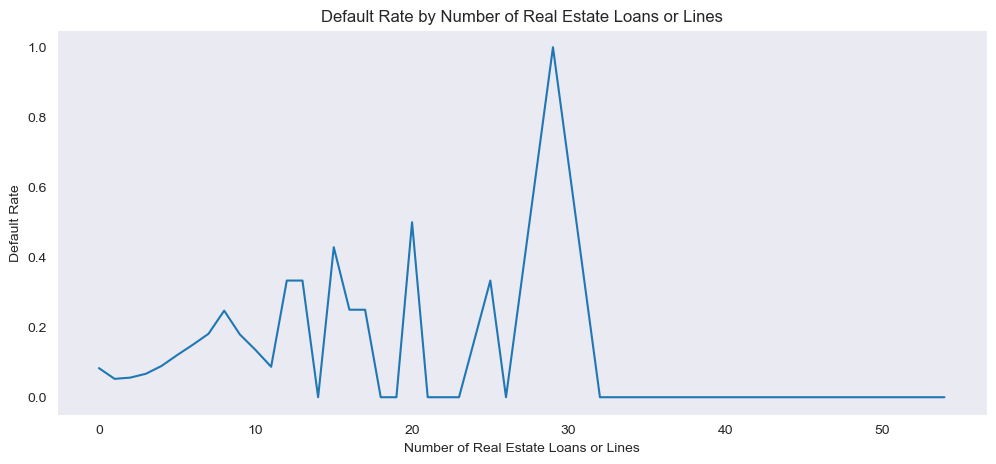

In [58]:
credit_default = df.groupby("NumberRealEstateLoansOrLines")["SeriousDlqin2yrs"].mean()

plt.figure(figsize=(12, 5))
plt.plot(credit_default.index, credit_default.values)

plt.xlabel("Number of Real Estate Loans or Lines")
plt.ylabel("Default Rate")
plt.title("Default Rate by Number of Real Estate Loans or Lines")
plt.grid()
plt.show()

In [59]:
df.groupby("NumberOfDependents")["SeriousDlqin2yrs"].mean()


NumberOfDependents
0.0     0.058629
1.0     0.073529
2.0     0.081139
3.0     0.088263
4.0     0.103774
5.0     0.091153
6.0     0.151899
7.0     0.098039
8.0     0.083333
9.0     0.000000
10.0    0.000000
13.0    0.000000
20.0    0.000000
Name: SeriousDlqin2yrs, dtype: float64

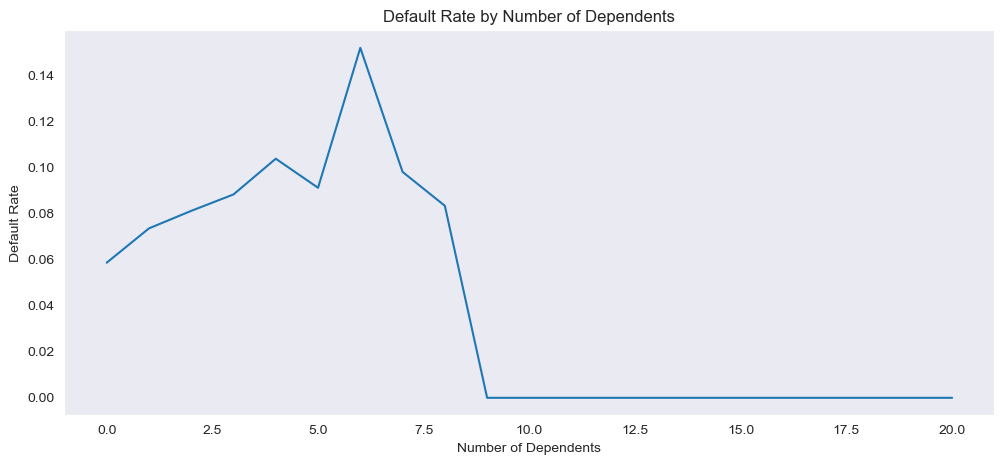

In [60]:
credit_default = df.groupby("NumberOfDependents")["SeriousDlqin2yrs"].mean()

plt.figure(figsize=(12, 5))
plt.plot(credit_default.index, credit_default.values)

plt.xlabel("Number of Dependents")
plt.ylabel("Default Rate")
plt.title("Default Rate by Number of Dependents")
plt.grid()
plt.show()

In [61]:
df["MonthlyIncome"].describe()


count    1.202690e+05
mean     6.670221e+03
std      1.438467e+04
min      0.000000e+00
25%      3.400000e+03
50%      5.400000e+03
75%      8.249000e+03
max      3.008750e+06
Name: MonthlyIncome, dtype: float64

In [62]:
df["MonthlyIncome"].quantile([0.5, 0.75, 0.90, 0.95, 0.99, 0.995, 0.999])

0.500     5400.000
0.750     8249.000
0.900    11666.000
0.950    14587.600
0.990    25000.000
0.995    35000.000
0.999    78395.748
Name: MonthlyIncome, dtype: float64

In [63]:
df["IncomeBin"] = pd.cut(
    df["MonthlyIncome"],
    bins=[0, 3000, 5000, 7500, 10000, 15000, 25000, 50000, float("inf")],
    labels=[
        "0-3K",
        "3K-5K",
        "5K-7.5K",
        "7.5K-10K",
        "10K-15K",
        "15K-25K",
        "25K-50K",
        "50K+"
    ]
)

df.groupby("IncomeBin", observed=True)["SeriousDlqin2yrs"].mean()

IncomeBin
0-3K        0.094286
3K-5K       0.082405
5K-7.5K     0.064975
7.5K-10K    0.051050
10K-15K     0.041964
15K-25K     0.044461
25K-50K     0.051903
50K+        0.056478
Name: SeriousDlqin2yrs, dtype: float64

In [64]:
df["DebtRatio"].quantile([0.25, 0.50, 0.75, 0.90, 0.95, 0.99])


0.25       0.175074
0.50       0.366508
0.75       0.868254
0.90    1267.000000
0.95    2449.000000
0.99    4979.040000
Name: DebtRatio, dtype: float64

In [65]:
df["DebtRatioBin"] = pd.qcut(
    df["DebtRatio"],
    q=10,
    duplicates="drop"
)

df.groupby("DebtRatioBin", observed=True)["SeriousDlqin2yrs"].mean()

DebtRatioBin
(-0.001, 0.0309]      0.053800
(0.0309, 0.134]       0.068200
(0.134, 0.214]        0.060333
(0.214, 0.287]        0.054067
(0.287, 0.367]        0.056133
(0.367, 0.468]        0.067400
(0.468, 0.649]        0.084128
(0.649, 4.0]          0.113317
(4.0, 1267.0]         0.060822
(1267.0, 329664.0]    0.049817
Name: SeriousDlqin2yrs, dtype: float64

In [66]:
df["UtilizationBin"] = pd.qcut(
    df["RevolvingUtilizationOfUnsecuredLines"],
    q=10,
    duplicates="drop"
)

df.groupby("UtilizationBin", observed=True)["SeriousDlqin2yrs"].mean()

UtilizationBin
(-0.001, 0.00297]    0.025200
(0.00297, 0.0192]    0.013600
(0.0192, 0.0435]     0.014000
(0.0435, 0.0832]     0.019133
(0.0832, 0.154]      0.023733
(0.154, 0.271]       0.034733
(0.271, 0.445]       0.052467
(0.445, 0.699]       0.088000
(0.699, 0.981]       0.165867
(0.981, 50708.0]     0.231667
Name: SeriousDlqin2yrs, dtype: float64

In [67]:
correlation = df.corr(numeric_only=True)["SeriousDlqin2yrs"].sort_values(
    ascending=False
)

correlation

SeriousDlqin2yrs                        1.000000
NumberOfTime30-59DaysPastDueNotWorse    0.125587
NumberOfTimes90DaysLate                 0.117175
NumberOfTime60-89DaysPastDueNotWorse    0.102261
NumberOfDependents                      0.046048
Unnamed: 0                              0.002801
RevolvingUtilizationOfUnsecuredLines   -0.001802
NumberRealEstateLoansOrLines           -0.007038
DebtRatio                              -0.007602
MonthlyIncome                          -0.019746
NumberOfOpenCreditLinesAndLoans        -0.029669
age                                    -0.115386
Name: SeriousDlqin2yrs, dtype: float64

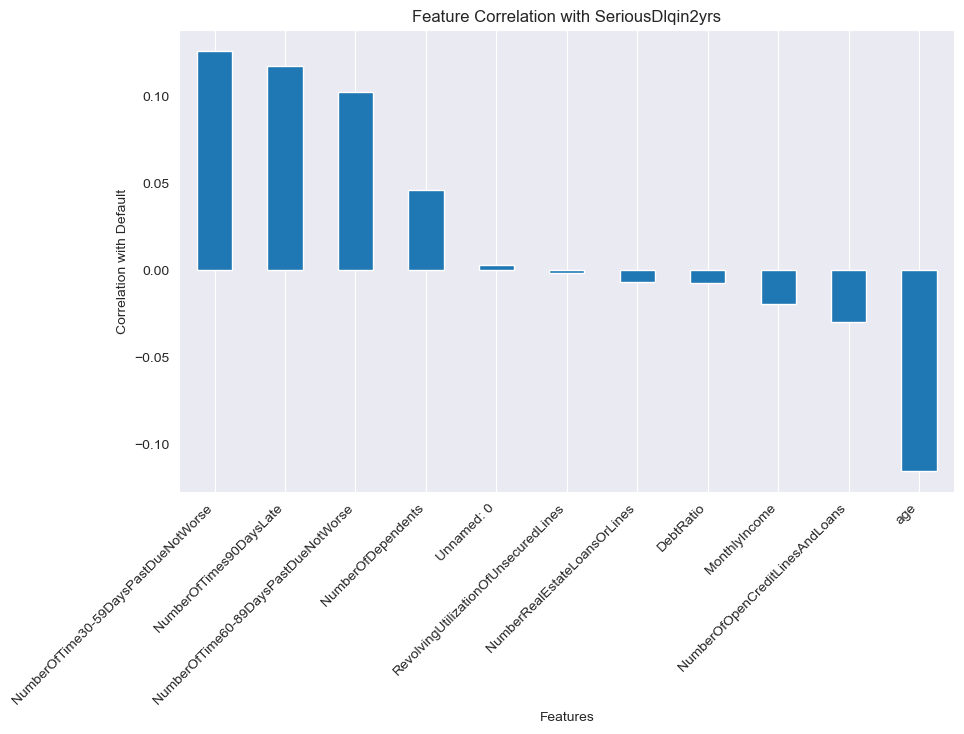

In [68]:
plt.figure(figsize=(10, 6))

correlation.drop("SeriousDlqin2yrs").plot(kind="bar")

plt.xlabel("Features")
plt.ylabel("Correlation with Default")
plt.title("Feature Correlation with SeriousDlqin2yrs")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y")
plt.show()

In [70]:
from sklearn.feature_selection import mutual_info_classif

X = df.drop(columns=["SeriousDlqin2yrs"]).select_dtypes(include="number")
y = df["SeriousDlqin2yrs"]

# Temporary imputation only for MI calculation
X_mi = X.fillna(X.median())

mi_scores = mutual_info_classif(
    X_mi,
    y,
    random_state=42
)

mi = pd.Series(
    mi_scores,
    index=X.columns
).sort_values(ascending=False)

mi

RevolvingUtilizationOfUnsecuredLines    0.036688
NumberOfTimes90DaysLate                 0.032752
NumberOfTime30-59DaysPastDueNotWorse    0.026883
NumberOfTime60-89DaysPastDueNotWorse    0.021480
age                                     0.008751
NumberRealEstateLoansOrLines            0.006999
NumberOfOpenCreditLinesAndLoans         0.004868
DebtRatio                               0.003856
MonthlyIncome                           0.003186
NumberOfDependents                      0.001550
Unnamed: 0                              0.000222
dtype: float64